# THÀNH VIÊN 4: ĐO LƯỜNG RỦI RO DANH MỤC & BACKTESTING (VaR, ES & BASEL)

**Vị trí trong chuỗi:** TV3 `dcc_matrices.npz` ($H_t$) + TV1 `log_returns.csv` → **TV4** → `var_es_timeseries.csv`, `backtest_results.csv` → TV5

| Bước | Nội dung | File output |
|---|---|---|
| 1 | Biến động danh mục $\sigma_{p,t}=\sqrt{w'H_tw}$ | (trong `var_es_timeseries.csv`) |
| 2 | VaR & ES 1 ngày, 95%/99%: Parametric Normal, Parametric Student-t, Historical Simulation | **`var_es_timeseries.csv`** |
| 3 | Backtest: số lần vi phạm, Kupiec POF, Christoffersen (độc lập & CC), Basel Traffic Light | **`backtest_results.csv`** |

**Quy ước:** lợi suất danh mục $r_{p,t}=w'r_t$; tổn thất $L_t=-r_{p,t}$; VaR, ES là **số dương**; trung bình lợi suất giả định = 0 (theo outline). Vi phạm khi $L_t > VaR_t$.
$H_t$ được xây từ thông tin đến $t-1$ ⇒ $VaR_t$ là **dự báo trước 1 ngày** và có thể so trực tiếp với $L_t$.
*Lưu ý trung thực khi báo cáo:* tham số GARCH/DCC ước lượng trên toàn mẫu (in-sample), nên backtest là "bán ngoài mẫu" – nêu rõ giới hạn này khi thuyết trình.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
from scipy.special import xlogy, gammaln

from project_config import *

OUT_DIR = TV4_DIR
log_ret = read_panel(require(FILES["log_returns"], "TV1_Data_EDA"))
z = np.load(require(FILES["dcc_npz"], "TV3_DCC"), allow_pickle=False)
dates = pd.to_datetime(z["dates"])
tickers = [str(t) for t in z["tickers"]]
H = z["H"]
assert list(log_ret.columns) == tickers and log_ret.index.equals(dates), "Output TV1 và TV3 không khớp ngày/mã"

w = get_weights(tickers)
print("Tỷ trọng danh mục w:", {k: round(float(v), 4) for k, v in w.items()})
r = log_ret.values
r_p = pd.Series(r @ w.values, index=dates, name="r_p")
loss = -r_p

Tỷ trọng danh mục w: {'FPT': 0.2, 'HPG': 0.2, 'MWG': 0.2, 'VCB': 0.2, 'VHM': 0.2}


## 1. Biến động có điều kiện của danh mục
**Tầng 1:** $\sigma_{p,t}=\sqrt{w'H_tw}=\sqrt{\sum_i\sum_j w_iw_j\sigma_{i,t}\sigma_{j,t}\rho_{ij,t}}$ – tổng hợp cả biến động riêng (TV2) lẫn tương quan động (TV3).
Đem so với "biến động không đa dạng hoá" $\sum_i w_i\sigma_{i,t}$ (tương đương giả định mọi ρ = 1) ⇒ thấy lợi ích đa dạng hoá theo thời gian.

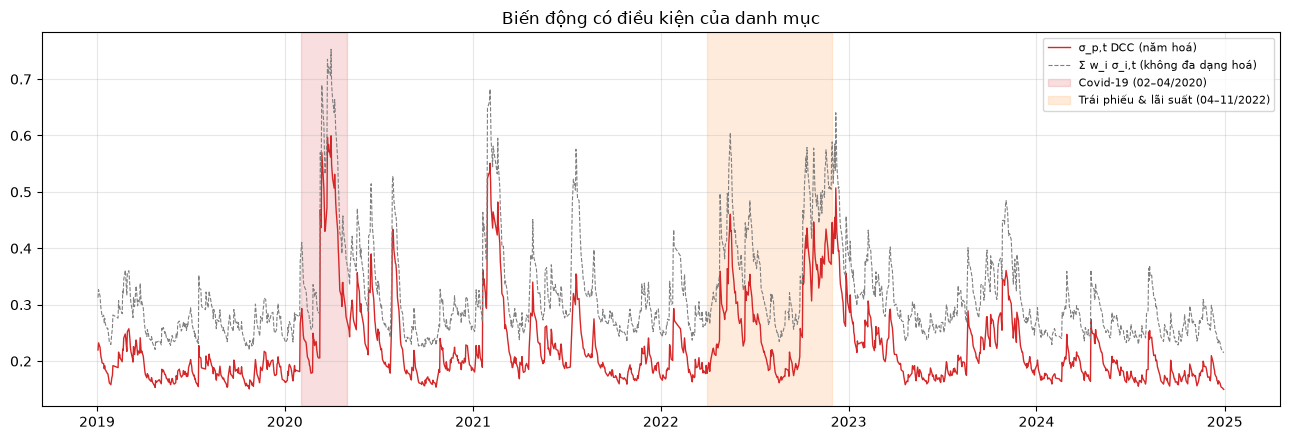

σ_p trung bình năm hoá: 22.47% | lợi ích đa dạng hoá trung bình: 29.6%


In [2]:
sigma_p = pd.Series(np.sqrt(np.einsum("i,tij,j->t", w.values, H, w.values)), index=dates, name="sigma_p")
sigma_i = np.sqrt(np.einsum("tii->ti", H))
sigma_undiv = pd.Series(sigma_i @ w.values, index=dates)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(dates, sigma_p * np.sqrt(TRADING_DAYS), color="tab:red", lw=1, label="σ_p,t DCC (năm hoá)")
ax.plot(dates, sigma_undiv * np.sqrt(TRADING_DAYS), color="grey", lw=0.8, ls="--", label="Σ w_i σ_i,t (không đa dạng hoá)")
shade_stress(ax)
ax.set_title("Biến động có điều kiện của danh mục"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "portfolio_volatility.png", dpi=150); plt.show()
print(f"σ_p trung bình năm hoá: {sigma_p.mean() * np.sqrt(TRADING_DAYS):.2%} | "
      f"lợi ích đa dạng hoá trung bình: {(1 - sigma_p / sigma_undiv).mean():.1%}")

## 2. VaR và ES 1 ngày

**Tầng 1 – Công thức** (α = xác suất vi phạm = 1 − mức tin cậy)
- **Normal:** $VaR_{\alpha,t}=z_{1-\alpha}\,\sigma_{p,t}$; $ES_{\alpha,t}=\sigma_{p,t}\,\dfrac{\phi(z_{1-\alpha})}{\alpha}$
- **Student-t chuẩn hoá** (phương sai 1, bậc tự do ν): $VaR=\sigma_{p,t}\sqrt{\tfrac{\nu-2}{\nu}}\;t_{\nu}^{-1}(1-\alpha)$;
  $ES=\sigma_{p,t}\sqrt{\tfrac{\nu-2}{\nu}}\;\dfrac{f_\nu(q)}{\alpha}\cdot\dfrac{\nu+q^2}{\nu-1}$, với $q=t_\nu^{-1}(1-\alpha)$. ν ước lượng bằng MLE trên $z_{p,t}=r_{p,t}/\sigma_{p,t}$.
- **Historical Simulation (HS):** $VaR_t$ = phân vị $(1-\alpha)$ của tổn thất trong cửa sổ lăn `HS_WINDOW` ngày trước $t$; $ES_t$ = trung bình các tổn thất ≥ VaR trong cửa sổ đó.

**Tầng 2:** output `var_es_timeseries.csv`: mỗi dòng 1 ngày; cột `VaR_<PP>_<CL>`, `ES_<PP>_<CL>` (ví dụ `VaR_Normal_99`), cùng `r_p`, `loss`, `sigma_p`.

**Tầng 3:** VaR_99 = 3% nghĩa là: với xác suất 99%, danh mục không lỗ quá 3% trong phiên kế tiếp. ES_99 = 4% nghĩa là: **nếu** rơi vào 1% ngày tệ nhất thì lỗ trung bình 4%. ES luôn ≥ VaR.

In [3]:
# ===================== 2a. ƯỚC LƯỢNG ν CHO STUDENT-t =====================
z_p = (r_p / sigma_p).values


def t_std_negll(nu, x):
    return -np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
                   - (nu + 1) / 2 * np.log1p(x ** 2 / (nu - 2)))


nu_p = optimize.minimize_scalar(t_std_negll, bounds=(2.1, 200), args=(z_p,), method="bounded").x
print(f"Phần dư chuẩn hoá danh mục z_p: std = {z_p.std():.3f}, kurtosis = {stats.kurtosis(z_p, fisher=False):.2f} "
      f"-> ν ước lượng = {nu_p:.2f}")

Phần dư chuẩn hoá danh mục z_p: std = 0.925, kurtosis = 5.48 -> ν ước lượng = 4.21


In [4]:
# ===================== 2b. TÍNH VaR / ES =====================
def var_es_normal(sig, cl):
    a = 1 - cl
    q = stats.norm.ppf(cl)
    return q * sig, sig * stats.norm.pdf(q) / a


def var_es_t(sig, cl, nu):
    a = 1 - cl
    q = stats.t.ppf(cl, nu)
    s = np.sqrt((nu - 2) / nu)
    return sig * s * q, sig * s * stats.t.pdf(q, nu) / a * (nu + q ** 2) / (nu - 1)


def var_es_hs(loss: pd.Series, cl, window=HS_WINDOW):
    """Chỉ dùng dữ liệu QUÁ KHỨ (shift 1) để không nhìn trước tương lai."""
    past = loss.shift(1)
    var = past.rolling(window).quantile(cl, interpolation="linear")
    es = past.rolling(window).apply(lambda x: x[x >= np.quantile(x, cl)].mean(), raw=True)
    return var, es


res = pd.DataFrame({"r_p": r_p, "loss": loss, "sigma_p": sigma_p})
for cl in CONF_LEVELS:
    tag = f"{int(round(cl * 100))}"
    res[f"VaR_Normal_{tag}"], res[f"ES_Normal_{tag}"] = var_es_normal(sigma_p, cl)
    res[f"VaR_t_{tag}"], res[f"ES_t_{tag}"] = var_es_t(sigma_p, cl, nu_p)
    res[f"VaR_HS_{tag}"], res[f"ES_HS_{tag}"] = var_es_hs(loss, cl)

METHODS = ["Normal", "t", "HS"]
# Cửa sổ so sánh chung: bỏ HS_WINDOW ngày đầu (HS chưa đủ dữ liệu) để mọi phương pháp backtest trên CÙNG số ngày
bt = res.dropna().copy()
print(f"Cửa sổ backtest chung: {bt.index.min().date()} -> {bt.index.max().date()} ({len(bt)} ngày)")
res.index.name = "Date"
res.to_csv(FILES["var_es"], encoding="utf-8-sig")

summary_var = pd.DataFrame({c: bt[c].mean() for c in bt.columns if c.startswith(("VaR", "ES"))}, index=["Trung bình"]).T
summary_var["Trung bình (%)"] = summary_var["Trung bình"] * 100
display(summary_var[["Trung bình (%)"]].round(3))

Cửa sổ backtest chung: 2020-01-16 -> 2024-12-30 (1202 ngày)


,Trung bình (%)
VaR_Normal_95,2.413
ES_Normal_95,3.026
VaR_t_95,2.234
ES_t_95,3.316
VaR_HS_95,2.414
ES_HS_95,3.661
VaR_Normal_99,3.413
ES_Normal_99,3.910
VaR_t_99,3.875
ES_t_99,5.327


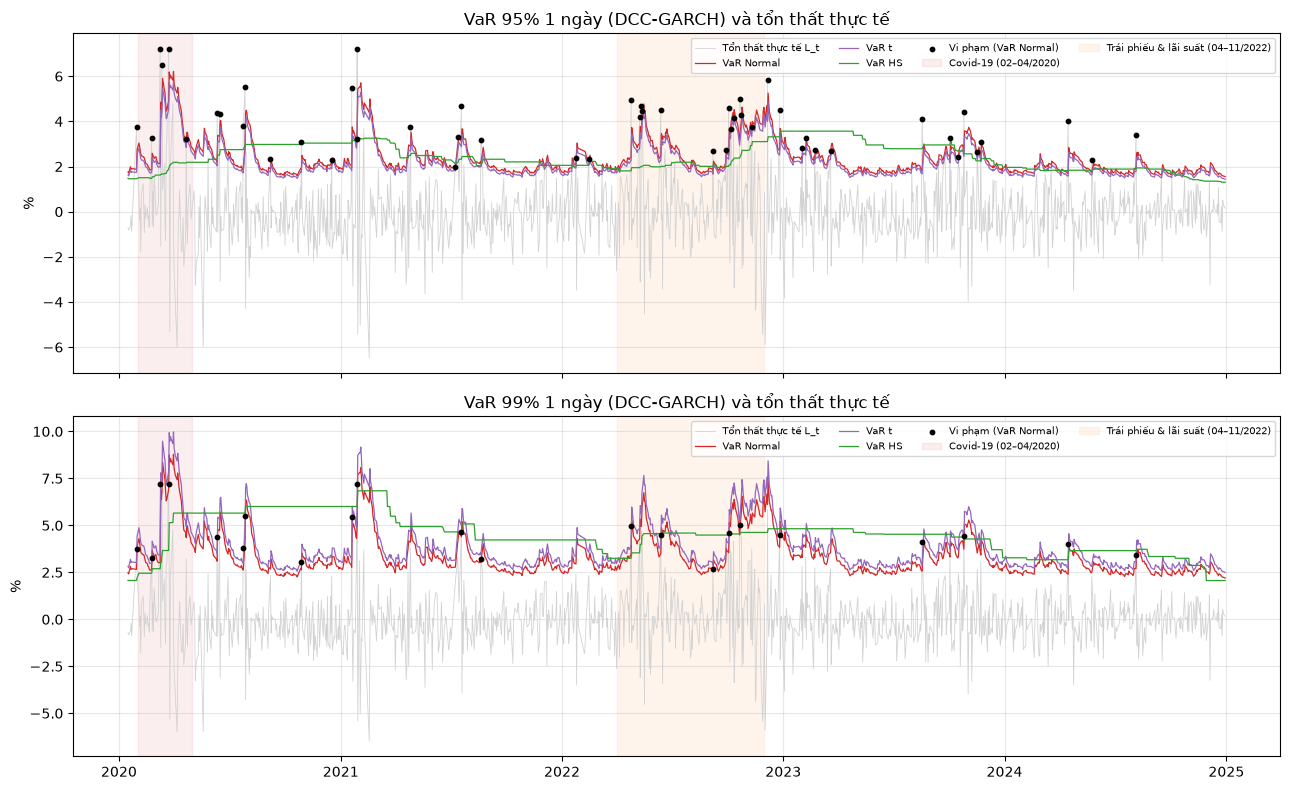

In [5]:
# ===================== 2c. ĐỒ THỊ VaR =====================
fig, axes = plt.subplots(len(CONF_LEVELS), 1, figsize=(13, 4 * len(CONF_LEVELS)), sharex=True)
for ax, cl in zip(np.atleast_1d(axes), CONF_LEVELS):
    tag = f"{int(round(cl * 100))}"
    ax.plot(bt.index, bt["loss"] * 100, color="lightgrey", lw=0.6, label="Tổn thất thực tế L_t")
    for m, c in zip(METHODS, ["tab:red", "tab:purple", "tab:green"]):
        ax.plot(bt.index, bt[f"VaR_{m}_{tag}"] * 100, lw=0.9, color=c, label=f"VaR {m}")
    br = bt["loss"] > bt[f"VaR_Normal_{tag}"]
    ax.scatter(bt.index[br], bt["loss"][br] * 100, color="black", s=10, zorder=3, label="Vi phạm (VaR Normal)")
    shade_stress(ax, alpha=0.08)
    ax.set_title(f"VaR {tag}% 1 ngày (DCC-GARCH) và tổn thất thực tế"); ax.set_ylabel("%"); ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=4, loc="upper right")
plt.tight_layout(); plt.savefig(OUT_DIR / "var_vs_loss.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Backtesting

**Tầng 1 – Công thức**
- Chuỗi vi phạm $I_t = 1\{L_t > VaR_t\}$; $x=\sum I_t$, $n$ = số ngày, $\hat p = x/n$.
- **Kupiec POF** (H0: $p=\alpha$): $LR_{POF} = -2\ln\!\big[(1-\alpha)^{n-x}\alpha^x\big] + 2\ln\!\big[(1-\hat p)^{n-x}\hat p^x\big] \sim \chi^2(1)$
- **Christoffersen độc lập** (H0: vi phạm hôm nay không phụ thuộc hôm qua): đếm $n_{ij}$ = số lần chuyển trạng thái i→j,
  $\pi_{01}=\frac{n_{01}}{n_{00}+n_{01}}$, $\pi_{11}=\frac{n_{11}}{n_{10}+n_{11}}$, $\pi=\frac{n_{01}+n_{11}}{\sum n_{ij}}$;
  $LR_{ind} = -2\ln\!\big[(1-\pi)^{n_{00}+n_{10}}\pi^{n_{01}+n_{11}}\big] + 2\ln\!\big[(1-\pi_{01})^{n_{00}}\pi_{01}^{n_{01}}(1-\pi_{11})^{n_{10}}\pi_{11}^{n_{11}}\big] \sim \chi^2(1)$
- **Conditional coverage:** $LR_{CC}=LR_{POF}+LR_{ind}\sim\chi^2(2)$
- **Basel Traffic Light** (VaR 99%, 250 ngày gần nhất): Xanh 0–4, Vàng 5–9, Đỏ ≥ 10 vi phạm. Cho cửa sổ/mức tin cậy khác: dùng xác suất nhị thức tích luỹ $P(X\le x)$: Xanh < 95%, Vàng < 99,99%, Đỏ còn lại (đúng nguyên tắc xây dựng bảng Basel).

**Tầng 3:** Kupiec p < 0,05 ⇒ số vi phạm khác kỳ vọng (nhiều hơn = **đánh giá thấp rủi ro**, ít hơn = **thổi phồng rủi ro**). Christoffersen p < 0,05 ⇒ vi phạm **xảy ra thành cụm** – mô hình phản ứng chậm khi biến động tăng.

In [6]:
# ===================== 3. CÁC HÀM KIỂM ĐỊNH =====================
def kupiec_pof(I, alpha):
    n, x = len(I), int(I.sum())
    p_hat = x / n
    ll0 = xlogy(n - x, 1 - alpha) + xlogy(x, alpha)
    ll1 = xlogy(n - x, 1 - p_hat) + xlogy(x, p_hat)
    LR = -2 * (ll0 - ll1)
    return LR, stats.chi2.sf(LR, 1)


def christoffersen_ind(I):
    I = np.asarray(I, dtype=int)
    prev, curr = I[:-1], I[1:]
    n00 = np.sum((prev == 0) & (curr == 0)); n01 = np.sum((prev == 0) & (curr == 1))
    n10 = np.sum((prev == 1) & (curr == 0)); n11 = np.sum((prev == 1) & (curr == 1))
    pi01 = n01 / (n00 + n01) if (n00 + n01) else 0
    pi11 = n11 / (n10 + n11) if (n10 + n11) else 0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll1 = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    LR = max(-2 * (ll0 - ll1), 0.0)
    return LR, stats.chi2.sf(LR, 1), dict(n00=n00, n01=n01, n10=n10, n11=n11)


def basel_zone(x, n, alpha):
    """Phân vùng theo xác suất nhị thức tích luỹ; trùng khớp bảng Basel 0–4/5–9/10+ khi n = 250, α = 1%."""
    cum = stats.binom.cdf(x, n, alpha)
    return "Xanh" if cum < 0.95 else ("Vàng" if cum < 0.9999 else "Đỏ")


def backtest(df, method, cl):
    tag = f"{int(round(cl * 100))}"
    alpha = 1 - cl
    I = (df["loss"] > df[f"VaR_{method}_{tag}"]).astype(int).values
    n, x = len(I), int(I.sum())
    LRp, pp = kupiec_pof(I, alpha)
    LRi, pi_, cnt = christoffersen_ind(I)
    LRc = LRp + LRi
    pc = stats.chi2.sf(LRc, 2)
    brk = df["loss"][I == 1]
    es = df[f"ES_{method}_{tag}"][I == 1]
    return {
        "Phương pháp": method, "Mức tin cậy": f"{tag}%", "Số ngày": n, "Vi phạm kỳ vọng": n * alpha,
        "Vi phạm thực tế": x, "Tỷ lệ vi phạm": x / n,
        "Kupiec LR": LRp, "Kupiec p": pp, "Christoffersen LR_ind": LRi, "Ind p": pi_,
        "LR_CC": LRc, "CC p": pc, "n11 (vi phạm liên tiếp)": cnt["n11"],
        "Basel (toàn kỳ)": basel_zone(x, n, alpha),
        # ES backtest đơn giản: tổn thất TB trong ngày vi phạm / ES dự báo TB (≈ 1 là tốt, > 1 = ES đánh giá thấp)
        "Loss TB khi vi phạm / ES TB": (brk.mean() / es.mean()) if x else np.nan,
        "Đánh giá": ("Đánh giá THẤP rủi ro" if (pp < ALPHA and x > n * alpha) else
                     "THỔI PHỒNG rủi ro" if (pp < ALPHA and x < n * alpha) else "Tần suất vi phạm phù hợp")
                    + ("; vi phạm THÀNH CỤM" if pi_ < ALPHA else ""),
    }


rows = [backtest(bt, m, cl) for cl in CONF_LEVELS for m in METHODS]
bt_table = pd.DataFrame(rows)

# Basel chuẩn: 250 ngày gần nhất, VaR 99%
last = bt.iloc[-BASEL_WINDOW:]
basel_rows = []
for m in METHODS:
    x = int((last["loss"] > last[f"VaR_{m}_99"]).sum())
    zone = "Xanh" if x <= 4 else ("Vàng" if x <= 9 else "Đỏ")
    plus = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0.40, 6: 0.50, 7: 0.65, 8: 0.75, 9: 0.85}.get(x, 1.0)
    basel_rows.append({"Phương pháp": m, "Cửa sổ": f"{last.index.min().date()} -> {last.index.max().date()}",
                       "Vi phạm VaR99 (250 ngày)": x, "Vùng Basel": zone, "Hệ số cộng (plus factor)": plus,
                       "Hệ số nhân vốn k = 3 + plus": 3 + plus})
basel_table = pd.DataFrame(basel_rows)
bt_table = bt_table.merge(basel_table[["Phương pháp", "Vùng Basel"]].assign(**{"Mức tin cậy": "99%"}),
                          on=["Phương pháp", "Mức tin cậy"], how="left").rename(columns={"Vùng Basel": "Basel (250 ngày cuối)"})

def color_zone(v):
    return {"Xanh": "background-color:#d4edda", "Vàng": "background-color:#fff3cd",
            "Đỏ": "background-color:#f8d7da"}.get(v, "")


sty = bt_table.style.format({c: "{:.4f}" for c in bt_table.columns if bt_table[c].dtype.kind == "f"})
sty_map = getattr(sty, "map", None) or sty.applymap
display(sty_map(color_zone, subset=["Basel (toàn kỳ)", "Basel (250 ngày cuối)"]))
display(basel_table)
bt_table.to_csv(FILES["backtest"], index=False, encoding="utf-8-sig")

,Phương pháp,Mức tin cậy,Số ngày,Vi phạm kỳ vọng,Vi phạm thực tế,Tỷ lệ vi phạm,Kupiec LR,Kupiec p,Christoffersen LR_ind,Ind p,LR_CC,CC p,n11 (vi phạm liên tiếp),Basel (toàn kỳ),Loss TB khi vi phạm / ES TB,Đánh giá,Basel (250 ngày cuối)
0,Normal,95%,1202,60.1000,51,0.0424,1.5255,0.2168,3.0412,0.0812,4.5667,0.1019,5,Xanh,1.1571,Tần suất vi phạm phù hợp,nan
1,t,95%,1202,60.1000,61,0.0507,0.0141,0.9054,6.2507,0.0124,6.2648,0.0436,8,Xanh,1.0071,Tần suất vi phạm phù hợp; vi phạm THÀNH CỤM,nan
2,HS,95%,1202,60.1000,63,0.0524,0.1451,0.7033,23.2231,0.0000,23.3682,0.0000,14,Xanh,1.0479,Tần suất vi phạm phù hợp; vi phạm THÀNH CỤM,nan
3,Normal,99%,1202,12.0200,22,0.0183,6.7206,0.0095,0.6573,0.4175,7.3779,0.0250,1,Vàng,1.1650,Đánh giá THẤP rủi ro,Xanh
4,t,99%,1202,12.0200,17,0.0141,1.8467,0.1742,1.4006,0.2366,3.2473,0.1972,1,Xanh,0.9230,Tần suất vi phạm phù hợp,Xanh
5,HS,99%,1202,12.0200,18,0.0150,2.6069,0.1064,9.8863,0.0017,12.4932,0.0019,3,Vàng,1.0879,Tần suất vi phạm phù hợp; vi phạm THÀNH CỤM,Xanh


,Phương pháp,Cửa sổ,Vi phạm VaR99 (250 ngày),Vùng Basel,Hệ số cộng (plus factor),Hệ số nhân vốn k = 3 + plus
0,Normal,2023-12-26 -> 2024-12-30,2,Xanh,0,3
1,t,2023-12-26 -> 2024-12-30,2,Xanh,0,3
2,HS,2023-12-26 -> 2024-12-30,1,Xanh,0,3


In [7]:
# ===================== 3b. VI PHẠM THEO NĂM / GIAI ĐOẠN =====================
brk = pd.DataFrame({f"{m}_{int(cl*100)}": (bt["loss"] > bt[f"VaR_{m}_{int(cl*100)}"]).astype(int)
                    for cl in CONF_LEVELS for m in METHODS})
by_year = brk.groupby(brk.index.year).agg(["sum"]).droplevel(1, axis=1)
by_year["Số ngày"] = brk.groupby(brk.index.year).size()
print("Số lần vi phạm theo năm:")
display(by_year)

stress_rows = {}
for name, (a, b) in STRESS_PERIODS.items():
    m = (brk.index >= a) & (brk.index <= b)
    stress_rows[name] = brk[m].mean()
stress_rows["Cả kỳ backtest"] = brk.mean()
breach_rate_period = pd.DataFrame(stress_rows).T
print("Tỷ lệ vi phạm theo giai đoạn (so với kỳ vọng 5% / 1%):")
display((breach_rate_period * 100).round(2))

Số lần vi phạm theo năm:


,Normal_95,t_95,HS_95,Normal_99,t_99,HS_99,Số ngày
2020,13,14,22,8,7,7,234
2021,8,12,10,4,2,2,229
2022,17,19,22,6,4,7,246
2023,10,11,5,2,2,1,247
2024,3,5,4,2,2,1,246


Tỷ lệ vi phạm theo giai đoạn (so với kỳ vọng 5% / 1%):


,Normal_95,t_95,HS_95,Normal_99,t_99,HS_99
Covid-19 (02–04/2020),8.20,8.20,22.95,4.92,3.28,8.20
Trái phiếu & lãi suất (04–11/2022),7.78,7.78,10.78,2.99,1.80,3.59
Cả kỳ backtest,4.24,5.07,5.24,1.83,1.41,1.50


In [8]:
# ===================== LƯU EXCEL =====================
with pd.ExcelWriter(OUT_DIR / "TV4_var_backtest.xlsx", engine="openpyxl") as xw:
    bt_table.to_excel(xw, sheet_name="Backtest", index=False)
    basel_table.to_excel(xw, sheet_name="Basel_250", index=False)
    summary_var.to_excel(xw, sheet_name="VaR_ES_TB")
    by_year.to_excel(xw, sheet_name="Vi_pham_theo_nam")
    breach_rate_period.to_excel(xw, sheet_name="Vi_pham_theo_giai_doan")
    res.to_excel(xw, sheet_name="VaR_ES_hang_ngay")
print("✔ Đã lưu kết quả TV4 vào:", OUT_DIR)

✔ Đã lưu kết quả TV4 vào: D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV4_VaR_Backtest


## 4. Diễn giải cốt lõi (đọc bảng Backtest ở trên)
- **Đánh giá thấp rủi ro?** Vi phạm thực tế > kỳ vọng và Kupiec p < 0,05 (thường gặp ở VaR Normal 99% do đuôi dày).
- **Thổi phồng rủi ro?** Vi phạm thực tế < kỳ vọng và Kupiec p < 0,05 (thường gặp ở VaR-t 95%) ⇒ giữ vốn dư thừa.
- **Vi phạm thành cụm?** Christoffersen p < 0,05 / n11 lớn – tập trung trong giai đoạn khủng hoảng (bảng theo giai đoạn).
- **Basel:** vùng Xanh ⇒ mô hình được chấp nhận; Vàng ⇒ tăng hệ số nhân vốn; Đỏ ⇒ phải xem lại mô hình.

### Gợi ý trả lời vấn đáp
**Câu 1 – VaR khác ES thế nào? Vì sao Basel III (FRTB) chuyển sang ES 97,5%?** VaR chỉ trả lời "ngưỡng lỗ không vượt quá với xác suất 99%", **không nói gì về mức lỗ khi đã vượt ngưỡng**; VaR cũng không *subadditive* (gộp danh mục có thể làm VaR tăng – trái nguyên lý đa dạng hoá). ES = trung bình tổn thất trong đuôi ⇒ nhạy với đuôi dày, là thước đo rủi ro nhất quán (coherent). Vì vậy FRTB dùng ES 97,5% (xấp xỉ VaR 99% khi phân phối chuẩn nhưng lớn hơn nhiều khi đuôi dày).

**Câu 2 – Christoffersen bị bác bỏ thì sao?** Vi phạm không độc lập mà đến **thành cụm**: mô hình cập nhật rủi ro chậm, khi thị trường chuyển sang trạng thái biến động cao, danh mục chịu **nhiều khoản lỗ vượt VaR liên tiếp** – rủi ro thanh khoản/margin call dồn dập. Cần mô hình phản ứng nhanh hơn (tăng α trong GARCH, dùng GJR, cửa sổ ngắn hơn) hoặc bổ sung stress test.

Rolling: WINDOW = 952, REFIT = 20, N_TEST = 500 (2022-12-22 -> 2024-12-30)
Mô hình biên (từ TV2): {'FPT': 'GJR-GARCH-t', 'HPG': 'GJR-GARCH-t', 'MWG': 'GJR-GARCH-t', 'VCB': 'GARCH-t', 'VHM': 'GARCH-t'}
✔ Xong 25 lần ước lượng lại trong 14s


,Refit từ,a,b,a+b,nu_p
0,2022-12-22,0.0350,0.9063,0.9413,3.8817
1,2023-01-27,0.0356,0.9033,0.9389,3.8029
2,2023-02-24,0.0337,0.9077,0.9414,3.6750
3,2023-03-24,0.0358,0.9018,0.9375,3.7888
4,2023-04-21,0.0369,0.9019,0.9388,3.7813
5,2023-05-25,0.0381,0.9001,0.9382,3.7707
6,2023-06-23,0.0419,0.8889,0.9308,3.7102
7,2023-07-21,0.0379,0.8953,0.9332,3.8013
8,2023-08-18,0.0349,0.9077,0.9426,3.8402
9,2023-09-19,0.0448,0.8705,0.9152,3.7572


,Phương pháp,Mức tin cậy,Số ngày,Vi phạm kỳ vọng,Vi phạm thực tế,Tỷ lệ vi phạm (%),Kupiec p,Christoffersen p,CC p,Basel (cả kỳ KĐ),Vi phạm 250 ngày cuối,Quantile loss (x1e4),VaR TB (%),ES TB (%),Đánh giá,"Basel (250 ngày cuối, VaR99)",Hạng QL
0,DCC-N,95%,500,25.0000,12,2.4000,0.0031,0.4419,0.0094,Xanh,3,14.1217,2.2357,2.8036,THỔI PHỒNG rủi ro,nan,3
1,DCC-t,95%,500,25.0000,14,2.8000,0.0142,0.3686,0.0329,Xanh,3,13.7665,2.0567,3.0723,THỔI PHỒNG rủi ro,nan,2
2,CCC-N,95%,500,25.0000,12,2.4000,0.0031,0.4419,0.0094,Xanh,3,14.2095,2.2745,2.8523,THỔI PHỒNG rủi ro,nan,4
3,EWMA-N,95%,500,25.0000,23,4.6000,0.6776,0.1359,0.3017,Xanh,11,12.8817,1.8846,2.3634,Tần suất vi phạm phù hợp,nan,1
4,HS,95%,500,25.0000,10,2.0000,0.0005,0.5225,0.0019,Xanh,4,14.3932,2.4002,3.3582,THỔI PHỒNG rủi ro,nan,5
5,DCC-N,99%,500,5.0000,5,1.0000,1.0000,0.7504,0.9507,Xanh,2,4.2233,3.1619,3.6225,Tần suất vi phạm phù hợp,Xanh,4
6,DCC-t,99%,500,5.0000,5,1.0000,1.0000,0.7504,0.9507,Xanh,2,4.2320,3.5917,4.9753,Tần suất vi phạm phù hợp,Xanh,5
7,CCC-N,99%,500,5.0000,5,1.0000,1.0000,0.7504,0.9507,Xanh,2,4.2039,3.2169,3.6855,Tần suất vi phạm phù hợp,Xanh,3
8,EWMA-N,99%,500,5.0000,5,1.0000,1.0000,0.7504,0.9507,Xanh,2,4.1511,2.6655,3.0538,Tần suất vi phạm phù hợp,Xanh,1
9,HS,99%,500,5.0000,2,0.4000,0.1250,0.8990,0.3059,Xanh,1,4.2029,3.9106,4.5302,Tần suất vi phạm phù hợp,Xanh,2


VaR 95%: tốt nhất theo quantile loss = EWMA-N | đạt cả Kupiec & Christoffersen: EWMA-N
VaR 99%: tốt nhất theo quantile loss = EWMA-N | đạt cả Kupiec & Christoffersen: DCC-N, DCC-t, CCC-N, EWMA-N, HS


,Mức tin cậy,Phương pháp,Tỷ lệ vi phạm trong mẫu (%),Tỷ lệ vi phạm ngoài mẫu (%),Kỳ vọng (%)
0,95%,DCC-N,4.24,2.4,5.0
1,95%,DCC-t,5.07,2.8,5.0
2,95%,HS,5.24,2.0,5.0
3,99%,DCC-N,1.83,1.0,1.0
4,99%,DCC-t,1.41,1.0,1.0
5,99%,HS,1.50,0.4,1.0


Sai lệch TB so với kỳ vọng: trong mẫu = 0.47 điểm %, ngoài mẫu = 1.40 điểm %
=> Ngoài mẫu kém hơn: backtest trong mẫu đã lạc quan, nên lấy kết quả ngoài mẫu làm kết luận chính.


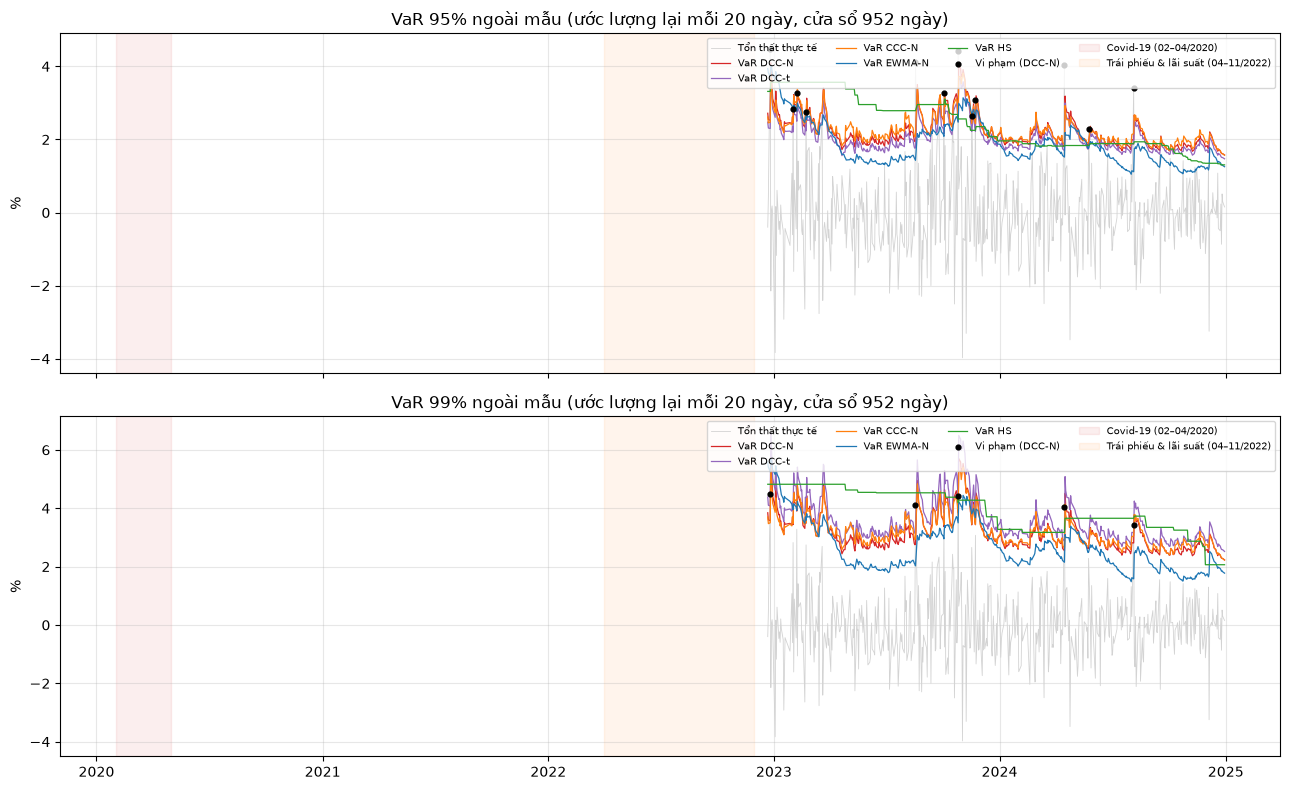

✔ Đã lưu kết quả ngoài mẫu TV4 vào: D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV4_VaR_Backtest


In [9]:
# CODE THÊM CHO THÀNH VIÊN 4 (Quỳnh) – DỰ BÁO VaR/ES DANH MỤC NGOÀI MẪU & BACKTEST
# Cách dùng: dán vào CUỐI notebook TV4_VaR_Backtest.ipynb, mỗi khối "# %%" là 1 ô (cell).
# Cần các ô phía trên đã chạy: log_ret, tickers, w, res, var_es_normal, var_es_t, t_std_negll,
#                               kupiec_pof, christoffersen_ind, basel_zone, color_zone.
# Đọc thêm từ TV2: garch_selected_models.csv (mô hình biên được chọn cho từng mã).
# =====================================================================================

# %% [markdown]
# ## 5. Dự báo rủi ro danh mục ngoài mẫu (Out-of-sample risk forecasting)
#
# **Tầng 1 – Vì sao cần?** Ở mục 2–3, tham số GARCH/DCC được ước lượng trên **toàn mẫu** rồi mới backtest ⇒ mô hình đã "nhìn thấy" chính những ngày đem ra kiểm định.
# Đề bài yêu cầu so sánh ít nhất 2 mô hình **ngoài mẫu**. Quy trình (giống template):
# 1. Kiểm định trên `N_TEST` ngày cuối. Cứ mỗi `REFIT` ngày, **ước lượng lại** toàn bộ mô hình trên `WINDOW` ngày gần nhất.
# 2. Giữa hai lần ước lượng, giữ nguyên tham số và lọc tiếp $\sigma_{i,t}$, $Q_t$ ⇒ $H_t$ chỉ dùng thông tin đến $t-1$.
# 3. So sánh 5 phương pháp trên **cùng** các ngày kiểm định:
#
# | Phương pháp | Biến động | Tương quan | Phân phối |
# |---|---|---|---|
# | **DCC-N** | GARCH biên (mô hình chọn ở TV2) | DCC(1,1) – thay đổi theo ngày | Normal |
# | **DCC-t** | như trên | như trên | Student-t (ν ước lượng trong cửa sổ) |
# | **CCC-N** | GARCH biên | Hằng số $\bar R$ của cửa sổ | Normal |
# | **EWMA-N** | RiskMetrics λ = 0,94 cho cả ma trận hiệp phương sai | | Normal |
# | **HS** | Phân vị lịch sử 250 ngày | | Không giả định |
#
# 4. **Đánh giá:** Kupiec, Christoffersen, Basel (như mục 3) + **hàm mất mát phân vị (quantile/tick loss)** để xếp hạng:
# $QL_t = (\alpha - I_t)\,(r_{p,t} + VaR_t)$, với $I_t = 1\{r_{p,t} < -VaR_t\}$. QL trung bình càng nhỏ càng tốt; nó phạt cả vi phạm (VaR quá thấp) lẫn VaR quá cao (giữ vốn thừa).
#
# **Tầng 2:** `fit_margin` (MLE GARCH/GJR – cùng công thức TV2), `fit_dcc` (QMLE bước 2 – cùng công thức TV3), `rolling_portfolio_forecast` trả về $H_t$ DCC, $H_t$ CCC, ν cho từng ngày kiểm định.
# Output: `oos_var_es.csv`, `oos_backtest.csv`, `oos_var_vs_loss.png`.
#
# **Tầng 3:** Mô hình tốt: tỷ lệ vi phạm ≈ α, Kupiec & Christoffersen p > 0,05, vùng Basel Xanh, QL nhỏ nhất. DCC thắng CCC ⇒ tương quan động **có giá trị dự báo** rủi ro danh mục, không chỉ khớp trong mẫu.

# %%
# ===================== 5.1 CẤU HÌNH & HÀM ƯỚC LƯỢNG (cùng công thức TV2/TV3) =====================
import time
import warnings
from scipy import optimize
from scipy.signal import lfilter

N_TEST = 500                                    # số ngày kiểm định (giống template)
REFIT = 20                                      # ước lượng lại mỗi 20 phiên
WINDOW = min(1000, len(log_ret) - N_TEST)       # cửa sổ ước lượng (tự thu nhỏ nếu mẫu ngắn)
LAMBDA_EWMA = 0.94
SC = 100                                        # ước lượng GARCH trên lợi suất % như TV2

garch_sel = pd.read_csv(require(FILES["garch_selected"], "TV2_GARCH"), index_col=0).loc[tickers]
SPEC = {tk: dict(gjr=bool(garch_sel.loc[tk, "GJR"]), dist=str(garch_sel.loc[tk, "Dist"])) for tk in tickers}
print(f"Rolling: WINDOW = {WINDOW}, REFIT = {REFIT}, N_TEST = {N_TEST} "
      f"({log_ret.index[-N_TEST].date()} -> {log_ret.index[-1].date()})")
print("Mô hình biên (từ TV2):", {tk: garch_sel.loc[tk, "Model"] for tk in tickers})


def g_filter(x, r, gjr, bc):
    """σ²_t của GARCH/GJR với tham số x = [mu, omega, alpha, (gamma), beta, (nu)], σ²_0 từ backcast bc."""
    mu, om, al = x[0], x[1], x[2]
    ga = x[3] if gjr else 0.0
    be = x[4] if gjr else x[3]
    e = r - mu
    z = np.empty_like(e)
    z[0] = om + (al + 0.5 * ga) * bc + be * bc
    z[1:] = om + (al + ga * (e[:-1] < 0)) * e[:-1] ** 2
    return lfilter([1.0], [1.0, -be], z), e


def g_negll(x, r, gjr, dist):
    s2, e = g_filter(x, r, gjr, np.mean((r - x[0]) ** 2))
    s2 = np.maximum(s2, 1e-12)
    if dist == "normal":
        return 0.5 * np.sum(np.log(2 * np.pi) + np.log(s2) + e ** 2 / s2)
    nu = x[-1]
    return -np.sum(gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
                   - 0.5 * np.log(s2) - (nu + 1) / 2 * np.log1p(e ** 2 / (s2 * (nu - 2))))


def fit_margin(r, gjr, dist, x0=None):
    """MLE GARCH/GJR (giống fit_garch của TV2, bỏ phần sai số chuẩn cho nhanh). Trả về vector tham số."""
    v = r.var()
    bnds = [(-np.inf, np.inf), (1e-8, 10 * v), (0, 1)] + ([(-1, 1)] if gjr else []) + [(0, 1)] + ([(2.05, 200)] if dist == "t" else [])
    ib = 4 if gjr else 3
    cons = [{"type": "ineq", "fun": lambda p: 0.99999 - (p[2] + (0.5 * p[3] if gjr else 0) + p[ib])}]
    if gjr:
        cons.append({"type": "ineq", "fun": lambda p: p[2] + p[3]})
    starts = [x0] if x0 is not None else []
    starts += [[r.mean(), v * 0.05, 0.05] + ([0.05] if gjr else []) + [0.90] + ([8.0] if dist == "t" else [])]
    best = None
    for s in starts:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            o = optimize.minimize(g_negll, s, args=(r, gjr, dist), method="SLSQP", bounds=bnds, constraints=cons,
                                  options={"maxiter": 500, "ftol": 1e-9})
        if np.isfinite(o.fun) and (best is None or o.fun < best.fun):
            best = o
    return best.x


def dcc_Q_path(a, b, e, Qbar):
    """Q_t, R_t (t = 0..T-1) với Q_0 = Q̄; R_t dùng ε đến t-1."""
    T, N = e.shape
    Q = np.empty((T, N, N)); Q[0] = Qbar
    for t in range(1, T):
        Q[t] = (1 - a - b) * Qbar + a * np.outer(e[t - 1], e[t - 1]) + b * Q[t - 1]
    d = 1 / np.sqrt(np.einsum("tii->ti", Q))
    return Q * d[:, :, None] * d[:, None, :]


def fit_dcc(e, x0=(0.02, 0.95)):
    Qbar = e.T @ e / len(e)

    def nll(th):
        a, b = th
        if a < 0 or b < 0 or a + b >= 0.9999:
            return 1e10
        R = dcc_Q_path(a, b, e, Qbar)
        _, logdet = np.linalg.slogdet(R)
        quad = np.einsum("ti,ti->t", e, np.linalg.solve(R, e[:, :, None])[:, :, 0])
        return 0.5 * np.sum(logdet + quad - np.einsum("ti,ti->t", e, e))

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        o = optimize.minimize(nll, x0, method="SLSQP", bounds=[(0, 0.5), (0, 0.9999)],
                              constraints=[{"type": "ineq", "fun": lambda th: 0.9999 - th[0] - th[1]}])
    return o.x, Qbar

# %%
# ===================== 5.2 VÒNG LẶP ROLLING: ƯỚC LƯỢNG LẠI GARCH + DCC MỖI REFIT NGÀY =====================
def rolling_portfolio_forecast(r):
    """r: T x N lợi suất (thập phân). Trả về H_dcc, H_ccc (N_TEST x N x N), nu_t (N_TEST), bảng tham số mỗi lần refit."""
    T, N = r.shape
    first = T - N_TEST
    H_dcc = np.empty((N_TEST, N, N)); H_ccc = np.empty((N_TEST, N, N)); nu_t = np.empty(N_TEST)
    log_rows, prev = [], {}
    for start in range(first, T, REFIT):
        end = min(start + REFIT, T)
        seg = r[start - WINDOW:end] * SC                    # cửa sổ ước lượng + các ngày cần dự báo
        win = seg[:WINDOW]
        sig = np.empty_like(seg); eps = np.empty_like(seg)
        for i, tk in enumerate(tickers):                    # Bước 1: GARCH biên từng mã
            x = fit_margin(win[:, i], **SPEC[tk], x0=prev.get(tk))
            prev[tk] = x
            s2, e = g_filter(x, seg[:, i], SPEC[tk]["gjr"], np.mean((win[:, i] - x[0]) ** 2))
            sig[:, i] = np.sqrt(s2); eps[:, i] = e / sig[:, i]
        (a, b), Qbar = fit_dcc(eps[:WINDOW], x0=prev.get("dcc", (0.02, 0.95)))   # Bước 2: DCC
        prev["dcc"] = (a, b)
        R = dcc_Q_path(a, b, eps, Qbar)                     # lọc Q_t qua cả cửa sổ + ngày dự báo
        Rbar = np.corrcoef(eps[:WINDOW].T)
        Hd = sig[:, :, None] * R * sig[:, None, :] / SC ** 2          # về đơn vị thập phân
        Hc = sig[:, :, None] * Rbar[None] * sig[:, None, :] / SC ** 2
        # ν cho DCC-t: MLE trên z_p = r_p / σ_p trong CỬA SỔ ƯỚC LƯỢNG (không dùng ngày kiểm định)
        sp_win = np.sqrt(np.einsum("i,tij,j->t", w.values, Hd[:WINDOW], w.values))
        zp = (r[start - WINDOW:start] @ w.values) / sp_win
        nu = optimize.minimize_scalar(t_std_negll, bounds=(2.1, 200), args=(zp,), method="bounded").x
        k = slice(start - first, end - first)
        H_dcc[k], H_ccc[k], nu_t[k] = Hd[WINDOW:], Hc[WINDOW:], nu
        log_rows.append({"Refit từ": log_ret.index[start].date(), "a": a, "b": b, "a+b": a + b, "nu_p": nu})
    return H_dcc, H_ccc, nu_t, pd.DataFrame(log_rows)


t0 = time.time()
H_dcc_oos, H_ccc_oos, nu_oos, refit_log = rolling_portfolio_forecast(log_ret.values)
print(f"✔ Xong {len(refit_log)} lần ước lượng lại trong {time.time() - t0:.0f}s")
display(refit_log.round(4))

# %%
# ===================== 5.3 EWMA COVARIANCE (RiskMetrics) =====================
def ewma_cov(r, lam=LAMBDA_EWMA):
    """S_t = λ S_{t-1} + (1-λ) r_{t-1} r_{t-1}'; khởi tạo bằng hiệp phương sai mẫu của cửa sổ đầu tiên."""
    T, N = r.shape
    S = np.empty((T, N, N))
    S[0] = np.cov(r[:WINDOW].T)
    for t in range(1, T):
        S[t] = lam * S[t - 1] + (1 - lam) * np.outer(r[t - 1], r[t - 1])
    return S[-N_TEST:]


H_ewma_oos = ewma_cov(log_ret.values)

# %%
# ===================== 5.4 VaR / ES NGOÀI MẪU CHO 5 PHƯƠNG PHÁP =====================
test_idx = log_ret.index[-N_TEST:]
wv = w.values
sp = {name: pd.Series(np.sqrt(np.einsum("i,tij,j->t", wv, Hm, wv)), index=test_idx)
      for name, Hm in [("DCC", H_dcc_oos), ("CCC", H_ccc_oos), ("EWMA", H_ewma_oos)]}

oos = pd.DataFrame({"r_p": res.loc[test_idx, "r_p"], "loss": res.loc[test_idx, "loss"],
                    "sigma_DCC": sp["DCC"], "sigma_CCC": sp["CCC"], "sigma_EWMA": sp["EWMA"], "nu_DCC": nu_oos})
OOS_METHODS = ["DCC-N", "DCC-t", "CCC-N", "EWMA-N", "HS"]
for cl in CONF_LEVELS:
    tag = f"{int(round(cl * 100))}"
    oos[f"VaR_DCC-N_{tag}"], oos[f"ES_DCC-N_{tag}"] = var_es_normal(sp["DCC"], cl)
    oos[f"VaR_DCC-t_{tag}"], oos[f"ES_DCC-t_{tag}"] = var_es_t(sp["DCC"], cl, nu_oos)
    oos[f"VaR_CCC-N_{tag}"], oos[f"ES_CCC-N_{tag}"] = var_es_normal(sp["CCC"], cl)
    oos[f"VaR_EWMA-N_{tag}"], oos[f"ES_EWMA-N_{tag}"] = var_es_normal(sp["EWMA"], cl)
    oos[f"VaR_HS_{tag}"], oos[f"ES_HS_{tag}"] = res.loc[test_idx, f"VaR_HS_{tag}"], res.loc[test_idx, f"ES_HS_{tag}"]
assert oos.notna().all().all(), "Còn NaN trong dự báo ngoài mẫu"
oos.index.name = "Date"
oos.to_csv(TV4_DIR / "oos_var_es.csv", encoding="utf-8-sig")

# %%
# ===================== 5.5 BACKTEST NGOÀI MẪU + QUANTILE LOSS =====================
def quantile_loss(r_p, var, alpha):
    hit = (r_p < -var).astype(float)
    return ((alpha - hit) * (r_p + var)).mean()


rows = []
for cl in CONF_LEVELS:
    tag, alpha = f"{int(round(cl * 100))}", 1 - cl
    for m in OOS_METHODS:
        I = (oos["loss"] > oos[f"VaR_{m}_{tag}"]).astype(int).values
        n, x = len(I), int(I.sum())
        LRp, pp = kupiec_pof(I, alpha)
        LRi, pi_, cnt = christoffersen_ind(I)
        pc = stats.chi2.sf(LRp + LRi, 2)
        last = I[-BASEL_WINDOW:]
        rows.append({
            "Phương pháp": m, "Mức tin cậy": f"{tag}%", "Số ngày": n, "Vi phạm kỳ vọng": n * alpha,
            "Vi phạm thực tế": x, "Tỷ lệ vi phạm (%)": 100 * x / n,
            "Kupiec p": pp, "Christoffersen p": pi_, "CC p": pc,
            "Basel (cả kỳ KĐ)": basel_zone(x, n, alpha),
            "Vi phạm 250 ngày cuối": int(last.sum()),
            "Quantile loss (x1e4)": quantile_loss(oos["r_p"], oos[f"VaR_{m}_{tag}"], alpha) * 1e4,
            "VaR TB (%)": oos[f"VaR_{m}_{tag}"].mean() * 100, "ES TB (%)": oos[f"ES_{m}_{tag}"].mean() * 100,
            "Đánh giá": ("Đánh giá THẤP rủi ro" if (pp < ALPHA and x > n * alpha) else
                         "THỔI PHỒNG rủi ro" if (pp < ALPHA and x < n * alpha) else "Tần suất vi phạm phù hợp")
                        + ("; vi phạm THÀNH CỤM" if pi_ < ALPHA else ""),
        })
oos_bt = pd.DataFrame(rows)
oos_bt.loc[oos_bt["Mức tin cậy"] == "99%", "Basel (250 ngày cuối, VaR99)"] = [
    "Xanh" if v <= 4 else ("Vàng" if v <= 9 else "Đỏ")
    for v in oos_bt.loc[oos_bt["Mức tin cậy"] == "99%", "Vi phạm 250 ngày cuối"]]
oos_bt["Basel (250 ngày cuối, VaR99)"] = oos_bt["Basel (250 ngày cuối, VaR99)"].fillna("")
oos_bt["Hạng QL"] = oos_bt.groupby("Mức tin cậy")["Quantile loss (x1e4)"].rank().astype(int)

sty = oos_bt.style.format({c: "{:.4f}" for c in oos_bt.columns if oos_bt[c].dtype.kind == "f"})
sty_map = getattr(sty, "map", None) or sty.applymap
display(sty_map(color_zone, subset=["Basel (cả kỳ KĐ)", "Basel (250 ngày cuối, VaR99)"]))
oos_bt.to_csv(TV4_DIR / "oos_backtest.csv", index=False, encoding="utf-8-sig")

for cl in CONF_LEVELS:
    sub = oos_bt[oos_bt["Mức tin cậy"] == f"{int(round(cl * 100))}%"].set_index("Phương pháp")
    print(f"VaR {int(cl*100)}%: tốt nhất theo quantile loss = {sub['Quantile loss (x1e4)'].idxmin()} | "
          f"đạt cả Kupiec & Christoffersen: {', '.join(sub.index[(sub['Kupiec p'] >= ALPHA) & (sub['Christoffersen p'] >= ALPHA)]) or 'không có'}")

# %%
# ===================== 5.6 SO SÁNH TRONG MẪU vs NGOÀI MẪU (DCC) =====================
ins = bt_table.set_index(["Phương pháp", "Mức tin cậy"])
cmp_rows = []
for cl in CONF_LEVELS:
    tag = f"{int(round(cl * 100))}%"
    for m_in, m_out in [("Normal", "DCC-N"), ("t", "DCC-t"), ("HS", "HS")]:
        o = oos_bt[(oos_bt["Phương pháp"] == m_out) & (oos_bt["Mức tin cậy"] == tag)].iloc[0]
        cmp_rows.append({"Mức tin cậy": tag, "Phương pháp": m_out,
                         "Tỷ lệ vi phạm trong mẫu (%)": 100 * ins.loc[(m_in, tag), "Tỷ lệ vi phạm"],
                         "Tỷ lệ vi phạm ngoài mẫu (%)": o["Tỷ lệ vi phạm (%)"],
                         "Kỳ vọng (%)": 100 * (1 - float(tag[:-1]) / 100)})
in_vs_out = pd.DataFrame(cmp_rows)
display(in_vs_out.round(2))
gap_in = (in_vs_out["Tỷ lệ vi phạm trong mẫu (%)"] - in_vs_out["Kỳ vọng (%)"]).abs().mean()
gap_out = (in_vs_out["Tỷ lệ vi phạm ngoài mẫu (%)"] - in_vs_out["Kỳ vọng (%)"]).abs().mean()
print(f"Sai lệch TB so với kỳ vọng: trong mẫu = {gap_in:.2f} điểm %, ngoài mẫu = {gap_out:.2f} điểm %")
print("=> Ngoài mẫu kém hơn: backtest trong mẫu đã lạc quan, nên lấy kết quả ngoài mẫu làm kết luận chính."
      if gap_out > gap_in + 0.25 else
      "=> Ngoài mẫu không kém hơn đáng kể: mô hình ổn định, kết quả trong mẫu không bị lạc quan quá mức.")

# %%
# ===================== 5.7 ĐỒ THỊ =====================
fig, axes = plt.subplots(len(CONF_LEVELS), 1, figsize=(13, 4 * len(CONF_LEVELS)), sharex=True)
for ax, cl in zip(np.atleast_1d(axes), CONF_LEVELS):
    tag = f"{int(round(cl * 100))}"
    ax.plot(test_idx, oos["loss"] * 100, color="lightgrey", lw=0.6, label="Tổn thất thực tế")
    for m, c in zip(OOS_METHODS, ["tab:red", "tab:purple", "tab:orange", "tab:blue", "tab:green"]):
        ax.plot(test_idx, oos[f"VaR_{m}_{tag}"] * 100, lw=0.9, color=c, label=f"VaR {m}")
    br = oos["loss"] > oos[f"VaR_DCC-N_{tag}"]
    ax.scatter(test_idx[br], oos["loss"][br] * 100, color="black", s=12, zorder=3, label="Vi phạm (DCC-N)")
    shade_stress(ax, alpha=0.08)
    ax.set_title(f"VaR {tag}% ngoài mẫu (ước lượng lại mỗi {REFIT} ngày, cửa sổ {WINDOW} ngày)")
    ax.set_ylabel("%"); ax.grid(alpha=0.3); ax.legend(fontsize=7, ncol=4, loc="upper right")
plt.tight_layout(); plt.savefig(TV4_DIR / "oos_var_vs_loss.png", dpi=150, bbox_inches="tight"); plt.show()

with pd.ExcelWriter(TV4_DIR / "TV4_out_of_sample.xlsx", engine="openpyxl") as xw:
    oos_bt.to_excel(xw, sheet_name="Backtest_ngoai_mau", index=False)
    in_vs_out.to_excel(xw, sheet_name="Trong_vs_ngoai_mau", index=False)
    refit_log.to_excel(xw, sheet_name="Tham_so_moi_lan_refit", index=False)
    oos.to_excel(xw, sheet_name="VaR_ES_ngoai_mau")
print("✔ Đã lưu kết quả ngoài mẫu TV4 vào:", TV4_DIR)

# %% [markdown]
# **Diễn giải (gợi ý viết mục 6.3):**
# - So sánh **DCC-N vs CCC-N**: cùng mô hình biên, chỉ khác tương quan động/hằng ⇒ chênh lệch vi phạm & quantile loss chính là **giá trị dự báo của DCC**.
# - So sánh **DCC-N vs DCC-t**: tác động của giả định đuôi dày lên VaR 99%.
# - So sánh với **EWMA** và **HS**: mô hình phức tạp có thực sự tốt hơn phương pháp đơn giản ngân hàng hay dùng không?
# - Bảng "trong mẫu vs ngoài mẫu": nếu tỷ lệ vi phạm ngoài mẫu cao hơn rõ rệt ⇒ backtest trong mẫu đã lạc quan; báo cáo nên lấy **kết quả ngoài mẫu làm kết luận chính**.
# - *Giới hạn:* giai đoạn kiểm định là `N_TEST` ngày cuối; muốn kiểm định cả khủng hoảng 2022 thì tăng `N_TEST` (ví dụ 700) – đổi lại cửa sổ ước lượng ngắn hơn.